# 6. Quantum chemistry with DMRG (block2)

**Goal.** Can the DMRG you ran on the Ising chain give the exact ground-state energy of a molecule, including cases where standard chemistry methods fail? Here you run it with [block2](https://github.com/block-hczhai/block2-preview), a DMRG package built for chemistry, on molecules small enough that the exact answer, full configuration interaction (FCI), is computed alongside. The Hamiltonians come from [PySCF](https://pyscf.org).

This notebook needs block2 and PySCF: `pip install block2 pyscf`.

*Further reading:* S. R. White and R. L. Martin, [arXiv:cond-mat/9808118](https://arxiv.org/abs/cond-mat/9808118); [J. Chem. Phys. 110, 4127 (1999)](https://doi.org/10.1063/1.478295) (the first DMRG for molecules); A. Baiardi and M. Reiher, [arXiv:1910.00137](https://arxiv.org/abs/1910.00137); [J. Chem. Phys. 152, 040903 (2020)](https://doi.org/10.1063/1.5129672) (review); H. Zhai et al., [arXiv:2310.03920](https://arxiv.org/abs/2310.03920); [J. Chem. Phys. 159, 234801 (2023)](https://doi.org/10.1063/5.0180424) (block2); Q. Sun et al., [arXiv:2002.12531](https://arxiv.org/abs/2002.12531); [J. Chem. Phys. 153, 024109 (2020)](https://doi.org/10.1063/5.0006074) (PySCF).

In [1]:
import math
import shutil
import tempfile
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from pyblock2._pyscf.ao2mo import integrals as itg
from pyblock2.driver.core import DMRGDriver, SymmetryTypes
from pyscf import cc, fci, gto, lo, scf

warnings.filterwarnings("ignore")
scratch = tempfile.mkdtemp()  # block2 keeps its MPS and environments on disk here
driver = DMRGDriver(scratch=scratch, symm_type=SymmetryTypes.SZ, n_threads=4)

## Quick start

A water molecule. As in notebook 5, you write $H$ term by term and the package builds the MPO. With $a^\dagger_{p\sigma}$ creating an electron of spin $\sigma$ in orbital $p$, the Hamiltonian of the electrons is

$$H = E_\text{core} + \sum_{pq,\sigma} h_{pq}\, a^\dagger_{p\sigma} a_{q\sigma} + \frac12 \sum_{pqrs,\sigma\tau} g_{pqrs}\, a^\dagger_{p\sigma} a^\dagger_{r\tau} a_{s\tau} a_{q\sigma}$$

(T. Helgaker, P. Jørgensen and J. Olsen, *Molecular Electronic-Structure Theory*, [Wiley (2000)](https://doi.org/10.1002/9781119019572)). It has a constant, terms that move one electron and terms that move two. The next section says what the numbers $h_{pq}$ and $g_{pqrs}$ are; PySCF computes them from the molecule:

In [2]:
mol = gto.M(atom="O 0 0 0; H 0 0.757 0.587; H 0 -0.757 0.587", basis="sto-3g", verbose=0)  # positions in angstrom
mf = scf.RHF(mol).run()  # Hartree-Fock: gives the orbitals
n_orb, n_elec, spin, ecore, h1e, g2e, _ = itg.get_rhf_integrals(mf, g2e_symm=1)


In [3]:
def chem_mpo(h1e, g2e, ecore):
    b = driver.expr_builder()
    b.add_const(ecore)
    for s in ["cd", "CD"]:  # one-electron terms, spin up and spin down
        b.add_sum_term(s, h1e)
    for s in ["ccdd", "cCDd", "CcdD", "CCDD"]:  # two-electron terms, all four spin pairs
        b.add_sum_term(s, 0.5 * g2e.transpose(0, 2, 3, 1))  # g[p,q,r,s] -> operator order p, r, s, q
    return driver.get_mpo(b.finalize(adjust_order=True, fermionic_ops="cdCD"), iprint=0)

block2 writes an operator string as letters: `c` and `d` create and annihilate a spin-up electron, `C` and `D` a spin-down one. `add_sum_term(string, array)` adds $\sum$ `array[i, j, ...]` times the string, with the indices in the order of the letters. So `"cd"` with `h1e` is $\sum_{pq} h_{pq}\, a^\dagger_{p\uparrow} a_{q\uparrow}$. The four strings of the two-electron term are the four spin choices $\sigma\tau$, and `transpose(0, 2, 3, 1)` puts $g_{pqrs}$ in the operator order $p, r, s, q$. `finalize` sorts every string into site order, with the fermion signs of the letters in `fermionic_ops`, and `get_mpo` compresses the sum into an MPO.

Now set up the chain of 7 orbitals, run DMRG, and compare with FCI:

In [4]:
t = time.perf_counter()
driver.initialize_system(n_sites=n_orb, n_elec=n_elec, spin=spin)
mpo = chem_mpo(h1e, g2e, ecore)
ket = driver.get_random_mps(tag="GS", bond_dim=100)
E = driver.dmrg(mpo, ket, n_sweeps=12, bond_dims=[100], noises=[1e-4] * 4 + [1e-5] * 4 + [0], thrds=[1e-10], iprint=0)
t_dmrg = time.perf_counter() - t

solver = fci.FCI(mf)
solver.conv_tol = 1e-12
E_fci = solver.kernel()[0]
print(f"{n_orb} orbitals, {n_elec} electrons")
print(f"E_DMRG = {E:.10f} Ha, E_FCI = {E_fci:.10f} Ha, error = {E - E_fci:.1e} Ha ({t_dmrg:.1f} s)")

mpo_qc = driver.get_qc_mpo(h1e=h1e, g2e=g2e, ecore=ecore, iprint=0)  # block2's built-in molecular MPO
E_qc = driver.dmrg(mpo_qc, driver.get_random_mps(tag="QC", bond_dim=100), n_sweeps=12, bond_dims=[100],
                   noises=[1e-4] * 4 + [1e-5] * 4 + [0], thrds=[1e-10], iprint=0)
print(f"with the built-in get_qc_mpo: E = {E_qc:.10f} Ha, difference = {E_qc - E:.1e} Ha")

7 orbitals, 10 electrons
E_DMRG = -75.0126471190 Ha, E_FCI = -75.0126471190 Ha, error = 1.2e-11 Ha (0.1 s)
with the built-in get_qc_mpo: E = -75.0126471190 Ha, difference = -1.1e-12 Ha


Energies are in hartree (Ha), the atomic unit; $1\,\text{Ha} = 27.2$ eV. The inputs, by their course names:

* `chem_mpo` is the MPO of $H$, built from its terms. block2 ships this molecular Hamiltonian ready-made as `get_qc_mpo`, which gives the same energy, as `TFIChain` did in notebook 5. The same `expr_builder` takes any other Hamiltonian written as operator strings.
* `get_random_mps(bond_dim=100)` is the starting MPS; `bond_dims=[100]` is $\chi$ for every sweep (block2 calls it $M$).
* `noises` is the mixer of notebook 5: a perturbation added for the first sweeps, then switched off. `thrds` is the Davidson tolerance (the eigensolver block2 uses instead of Lanczos).
* `SymmetryTypes.SZ` stores tensors in blocks of fixed electron number and fixed $S_z$, like TeNPy's `conserve`.

The rest of the notebook says what `h1e` and `g2e` are, why this is a chain problem, when it matters, and what to check.

## Quantum chemistry for a DMRG person

### What is being solved

The nuclei are held fixed, and we want the lowest energy of the electrons. Choose a set of $K$ orbitals (one-electron wavefunctions) $\phi_p$. In second quantization the Hamiltonian is the one in the quick start.

* $h_{pq}$ (`h1e`, a $K\times K$ matrix) moves one electron from orbital $q$ to $p$. It holds the kinetic energy and the attraction to the nuclei.
* $g_{pqrs}$ (`g2e`, $K^4$ numbers) is the Coulomb repulsion between two electrons, one moving $q\to p$ and the other $s\to r$. It is the integral $\int \phi_p\phi_q(1)\,\frac{1}{r_{12}}\,\phi_r\phi_s(2)$, the order chemists write as $(pq|rs)$.
* $E_\text{core}$ is the repulsion between the nuclei, a constant.

The two arrays are integrals over the orbitals. PySCF computes them, and that is all DMRG ever sees of the molecule:

In [5]:
print("h1e:", h1e.shape, "  g2e:", g2e.shape)
print(f"E_core = {ecore:.6f} Ha, nuclear repulsion = {mol.energy_nuc():.6f} Ha")

h1e: (7, 7)   g2e: (7, 7, 7, 7)
E_core = 9.188258 Ha, nuclear repulsion = 9.188258 Ha


### Where the orbitals come from

* **Basis set.** A fixed list of functions centred on the atoms. STO-3G, the smallest, has one function per atomic orbital of a free atom: 1s and 2s, 2p for oxygen, 1s for each hydrogen, 7 in all (W. J. Hehre, R. F. Stewart and J. A. Pople, [J. Chem. Phys. 51, 2657 (1969)](https://doi.org/10.1063/1.1672392)). Larger basis sets add more functions and are more accurate.
* **Hartree–Fock** (`scf.RHF`) finds the best state that is a single Slater determinant: each electron in its own orbital, with no correlation. Its orbitals (combinations of the basis functions) are the $\phi_p$ used above. The $n_\text{elec}/2$ lowest are doubly occupied, the rest are empty (A. Szabo and N. S. Ostlund, *Modern Quantum Chemistry*, Dover (1996), chapter 3).

So the Hartree–Fock energy is the expectation value of $H$ in that determinant. Written out with the integrals, summing over the occupied orbitals $i, j$, it is $E_\text{core} + 2\sum_i h_{ii} + \sum_{ij}\big[2g_{iijj} - g_{ijji}\big]$ (Szabo and Ostlund, chapter 3): direct Coulomb minus exchange. Checking it confirms the meaning of `h1e` and `g2e`:

In [6]:
occ = slice(0, n_elec // 2)
g_occ = g2e[occ, occ, occ, occ]
E_hf = ecore + 2 * np.trace(h1e[occ, occ]) + 2 * np.einsum("iijj->", g_occ) - np.einsum("ijji->", g_occ)
print(f"from the integrals: {E_hf:.10f} Ha, PySCF RHF: {mf.e_tot:.10f} Ha")
print(f"correlation energy E_FCI - E_HF = {E_fci - mf.e_tot:.4f} Ha")

from the integrals: -74.9630631297 Ha, PySCF RHF: -74.9630631297 Ha
correlation energy E_FCI - E_HF = -0.0496 Ha


The **correlation energy** is everything Hartree–Fock misses. It is small here, but it decides chemistry: $0.05$ Ha is about 30 kcal/mol, the size of a reaction energy.

**FCI** is exact diagonalization: $H$ in the basis of all ways to put $N_\uparrow$ and $N_\downarrow$ electrons into $K$ orbitals, $\binom{K}{N_\uparrow}\binom{K}{N_\downarrow}$ states. That number explodes with $K$:

In [7]:
systems = [("H2O, STO-3G", 7, 10), ("N2, STO-3G", 10, 14), ("N2, cc-pVDZ", 28, 14), ("benzene, cc-pVDZ", 114, 42)]
for name, K, n in systems:
    print(f"{name:17s} K = {K:3d}: FCI dimension {math.comb(K, n // 2) ** 2:.1e}")

H2O, STO-3G       K =   7: FCI dimension 4.4e+02
N2, STO-3G        K =  10: FCI dimension 1.4e+04
N2, cc-pVDZ       K =  28: FCI dimension 1.4e+12
benzene, cc-pVDZ  K = 114: FCI dimension 1.9e+45


A realistic basis set (cc-pVDZ) is out of reach of FCI even for N$_2$. The usual compromise is an **active space**: keep the lowest orbitals doubly occupied (the core), drop the highest, and solve exactly only in a window of orbitals near the Fermi level. `get_rhf_integrals(mf, ncore=..., ncas=...)` returns the Hamiltonian of such a window, and $E_\text{core}$ then also includes the energy of the frozen core electrons. FCI on an active space is called CASCI. DMRG's job is to replace FCI when the active space is too big for it.

### The molecule as a chain

Line the $K$ orbitals up, and the problem has exactly the shape of the TFIM chain:

| | TFIM chain | molecule |
|---|---|---|
| site | spin $i$ | orbital $p$ |
| local states | $d = 2$ | $d = 4$: empty, $\uparrow$, $\downarrow$, $\uparrow\downarrow$ |
| terms in $H$ | nearest neighbours | every pair and quadruple of orbitals |
| MPO bond dimension | $D = 3$ | grows as $K^2$ |
| site order | fixed by the lattice | your choice |

Fermion signs are handled inside the MPO (a Jordan–Wigner string), as for any fermionic chain. Here are the four states of one site, labelled by particle number $N$ and $S_z$:

In [8]:
print(driver.basis[0])

{< N=0 SZ=0 PG=0 >: 1, < N=1 SZ=1/2 PG=0 >: 1, < N=1 SZ=-1/2 PG=0 >: 1, < N=2 SZ=0 PG=0 >: 1}


The MPO is where chemistry differs most. In the TFIM, $D = 3$ because each bond only has to remember "nothing yet", "an $X$ waiting for its partner" or "done". Here an operator string $a^\dagger_p a^\dagger_r a_s a_q$ can have any of its four operators on either side of a cut, so the MPO has to carry many partial products across each bond. However the MPO is built, its bond dimension grows as $K^2$ (G. K.-L. Chan et al., [arXiv:1605.02611](https://arxiv.org/abs/1605.02611); [J. Chem. Phys. 145, 014102 (2016)](https://doi.org/10.1063/1.4955108)). Hydrogen chains $\mathrm{H}_K$ in STO-3G have one orbital per atom, so they give any $K$:

In [9]:
def hydrogen_chain(n_atoms, spacing):
    return gto.M(atom=[("H", (0, 0, i * spacing)) for i in range(n_atoms)], basis="sto-3g", verbose=0)


Ks, Ds = [4, 6, 8, 10, 12, 14, 16], []
for K in Ks:
    m = scf.RHF(hydrogen_chain(K, 1.0)).run()
    _, ne, sp, ec, h1, g2, _ = itg.get_rhf_integrals(m, g2e_symm=1)
    driver.initialize_system(n_sites=K, n_elec=ne, spin=sp)
    Ds.append(max(chem_mpo(h1, g2, ec).get_bond_dims()))
print("K     :", Ks)
print("max D :", Ds)
print("fit   :", np.round(np.polyfit(Ks, Ds, 2), 6), "(coefficients of K^2, K, 1)")

K     : [4, 6, 8, 10, 12, 14, 16]
max D : [51, 99, 163, 243, 339, 451, 579]
fit   : [2. 4. 3.] (coefficients of K^2, K, 1)


The middle bond has $D = 2K^2 + 4K + 3$ exactly, against $D = 3$ for the TFIM. A matvec costs $\chi^3 D d^2$, so a long-range Hamiltonian makes every DMRG step more expensive. That cost is polynomial, though. The real question is the same as for spin chains: how much entanglement the ground state has across each cut, which sets $\chi$.

## Why DMRG matters here: breaking a bond

Near its equilibrium geometry, a molecule is described well by one Slater determinant plus corrections. The standard corrections are coupled-cluster methods: CCSD (G. D. Purvis and R. J. Bartlett, [J. Chem. Phys. 76, 1910 (1982)](https://doi.org/10.1063/1.443164)) and CCSD(T), which adds triple excitations perturbatively (K. Raghavachari et al., [Chem. Phys. Lett. 157, 479 (1989)](https://doi.org/10.1016/S0009-2614(89)87395-6)). CCSD(T) is the method chemists use by default. All of them start from Hartree–Fock.

Stretch the triple bond of N$_2$, and many determinants become equally important. We follow RHF, CCSD, CCSD(T), DMRG ($\chi = 200$) and FCI along the bond length $R$, in STO-3G (10 orbitals, 14 electrons, so FCI takes a fraction of a second):

In [10]:
def fci_solve(mf):
    solver = fci.FCI(mf)
    solver.conv_tol = 1e-12
    solver.nroots = 3  # several roots: a single-root solve can miss the ground state at stretched bonds
    energies, vectors = solver.kernel()
    return energies[0], vectors[0]


def run_dmrg(h1e, g2e, ecore, n_elec, chi, n_sweeps=12):
    driver.initialize_system(n_sites=h1e.shape[0], n_elec=n_elec, spin=0)
    mpo = chem_mpo(h1e, g2e, ecore)
    ket = driver.get_random_mps(tag="GS", bond_dim=chi)
    noises = [1e-4] * 4 + [1e-5] * 4 + [0]
    E = driver.dmrg(mpo, ket, n_sweeps=n_sweeps, bond_dims=[chi], noises=noises, thrds=[1e-10], iprint=0)
    discarded = driver.get_dmrg_results()[1][-1]  # largest discarded weight in the last sweep
    return E, discarded, ket


def nitrogen(R):
    return gto.M(atom=f"N 0 0 0; N 0 0 {R}", basis="sto-3g", verbose=0)


Rs = [0.9, 1.0, 1.1, 1.25, 1.4, 1.6, 1.8, 2.0, 2.2, 2.5, 2.8]
rows = []
t = time.perf_counter()
for R in Rs:
    mf = scf.RHF(nitrogen(R)).run()
    E_fci, civec = fci_solve(mf)
    ccsd = cc.CCSD(mf).run()
    E_cc, E_t = (ccsd.e_tot, ccsd.e_tot + ccsd.ccsd_t()) if ccsd.converged else (np.nan, np.nan)
    _, ne, _, ec, h1, g2, _ = itg.get_rhf_integrals(mf, g2e_symm=1)
    E_dmrg = run_dmrg(h1, g2, ec, ne, chi=200)[0]
    rows.append(dict(R=R, fci=E_fci, rhf=mf.e_tot, ccsd=E_cc, t=E_t, dmrg=E_dmrg, conv=ccsd.converged,
                     w_hf=civec[0, 0] ** 2))
print(f"{len(Rs)} geometries in {time.perf_counter() - t:.0f} s\n")
print("   R    weight of HF   RHF - FCI   CCSD - FCI   CCSD(T) - FCI   DMRG - FCI")
for r in rows:
    flag = "" if r["conv"] else "  (CCSD does not converge)"
    cc_err = [f"{r[k] - r['fci']:+.4f}" if r["conv"] else "-" for k in ("ccsd", "t")]
    print(f"{r['R']:5.2f}   {r['w_hf']:12.3f}   {r['rhf'] - r['fci']:9.3f}   {cc_err[0]:>10s}"
          f"   {cc_err[1]:>13s}   {r['dmrg'] - r['fci']:+10.1e}{flag}")

11 geometries in 13 s

   R    weight of HF   RHF - FCI   CCSD - FCI   CCSD(T) - FCI   DMRG - FCI
 0.90          0.954       0.106      +0.0017         +0.0007     +1.5e-11
 1.00          0.938       0.130      +0.0026         +0.0012     +4.4e-11
 1.10          0.917       0.158      +0.0039         +0.0022     +4.5e-12
 1.25          0.872       0.207      +0.0071         +0.0048     +1.0e-11
 1.40          0.804       0.265      +0.0115         +0.0087     +2.2e-11
 1.60          0.649       0.357      +0.0127         +0.0097     +2.4e-11
 1.80          0.426       0.466      -0.0195         -0.0228     +7.3e-11
 2.00          0.247       0.584      -0.1018         -0.1085     +8.3e-11
 2.20          0.154       0.693            -               -     +1.0e-10  (CCSD does not converge)
 2.50          0.099       0.823            -               -     -3.4e-09  (CCSD does not converge)
 2.80          0.078       0.915            -               -     +7.1e-11  (CCSD does not converge)

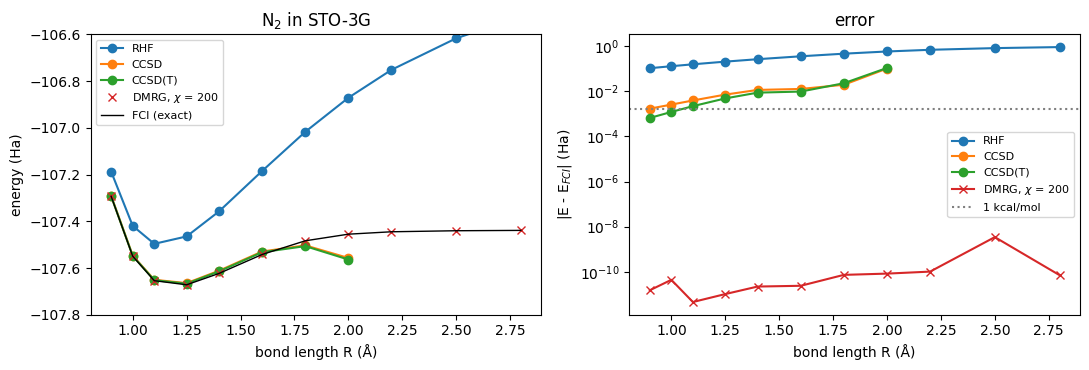

In [11]:
def col(k):
    return np.array([r[k] for r in rows])


fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, lab in [("rhf", "RHF"), ("ccsd", "CCSD"), ("t", "CCSD(T)"), ("dmrg", "DMRG, $\\chi$ = 200")]:
    ax[0].plot(Rs, col(k), "o-" if k != "dmrg" else "x", label=lab)
    ax[1].semilogy(Rs, np.maximum(np.abs(col(k) - col("fci")), 1e-12), "o-" if k != "dmrg" else "x-", label=lab)
ax[0].plot(Rs, col("fci"), "k-", lw=1, label="FCI (exact)")
ax[0].set(xlabel="bond length R (Å)", ylabel="energy (Ha)", title="N$_2$ in STO-3G", ylim=(-107.8, -106.6))
ax[1].axhline(1.6e-3, color="gray", ls=":", label="1 kcal/mol")
ax[1].set(xlabel="bond length R (Å)", ylabel="|E - E$_{FCI}$| (Ha)", title="error")
ax[0].legend(fontsize=8)
ax[1].legend(fontsize=8)
plt.tight_layout()

What the table shows:

* **Why the single-reference methods fail.** The weight of the Hartree–Fock determinant in the exact state, $|c_0|^2$, falls from about 0.9 at equilibrium ($R \approx 1.1$ Å) to well below one half once the bond is broken. A method that starts from that one determinant and adds corrections is then expanding around the wrong state.
* **RHF** misses more and more energy as $R$ grows, close to 1 Ha at 2.8 Å: two neutral N atoms cannot be described by doubly occupied orbitals shared between them.
* **CCSD(T)** is good to 1–2 mHa near equilibrium, and the error grows to 10 mHa at 1.6 Å. Then it fails: at 1.8 and 2 Å it lands *below* the exact energy, by 0.1 Ha at 2 Å (coupled cluster is not variational, so nothing stops it), and from 2.2 Å on CCSD no longer converges at all (blank in the table and the plot).
* **DMRG** is variational and does not care how many determinants matter, only how entangled the state is across each cut. It matches FCI to better than $10^{-8}$ Ha at every $R$.

The point is not N$_2$ in STO-3G, where FCI is cheap. It is that DMRG's cost does not grow with the number of important determinants, so it keeps working when $K$ is too big for FCI, as long as the entanglement stays moderate.

## What to check before trusting it

As in notebook 5, the checks are yours. Two of them are special to chemistry: the order of the orbitals, and which orbitals carry the entanglement. We use the chain $\mathrm{H}_{10}$ with spacing 1.5 Å, a stretched chain of hydrogen atoms (10 orbitals, FCI still in a fraction of a second).

### Orbital order

The Hartree–Fock orbitals are delocalized over the whole molecule, ordered by energy. A chain made of them is long-ranged in every sense. An alternative is to **localize** the orbitals (Boys localization: rotate the occupied and the empty orbitals among themselves to make each as compact as possible; J. M. Foster and S. F. Boys, [Rev. Mod. Phys. 32, 300 (1960)](https://doi.org/10.1103/RevModPhys.32.300)), and order them along the chain. FCI and the Hartree–Fock energy are unchanged by such a rotation; only the chain is different. Look at the hopping matrix $|h_{pq}|$ in each basis:

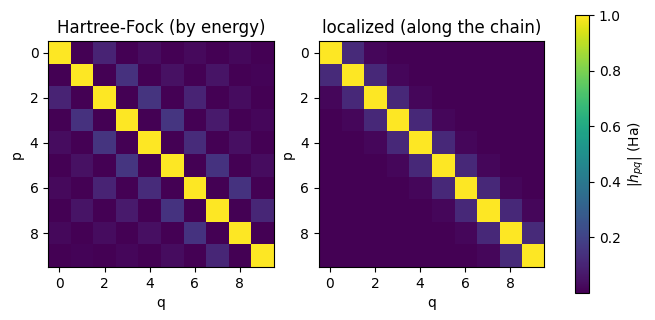

chi =  8: error with Hartree-Fock orbitals = 2.1e-01, with localized orbitals = 4.6e-03


chi = 16: error with Hartree-Fock orbitals = 1.1e-01, with localized orbitals = 2.7e-04


chi = 32: error with Hartree-Fock orbitals = 7.3e-02, with localized orbitals = 7.8e-06


chi = 64: error with Hartree-Fock orbitals = 2.5e-02, with localized orbitals = 1.2e-07


In [12]:
mol = hydrogen_chain(10, 1.5)
mf_h10 = scf.RHF(mol).run()
E_fci_h10 = fci_solve(mf_h10)[0]

C = lo.Boys(mol, mf_h10.mo_coeff).kernel()  # localize
z = np.einsum("pi,pi->i", C, mol.intor("int1e_r")[2] @ C)  # centre of each orbital along the chain
C = C[:, np.argsort(z)]


def integrals(mf, mo_coeff):
    m = mf.copy()
    m.mo_coeff = mo_coeff
    return itg.get_rhf_integrals(m, g2e_symm=1)[3:6]  # ecore, h1e, g2e


bases = {
    "Hartree-Fock (by energy)": integrals(mf_h10, mf_h10.mo_coeff),
    "localized (along the chain)": integrals(mf_h10, C),
}
fig, ax = plt.subplots(1, 2, figsize=(8, 3.6))
for a, (name, (_, h1, _)) in zip(ax, bases.items(), strict=True):
    im = a.imshow(np.abs(h1), cmap="viridis", vmax=1.0)
    a.set(title=name, xlabel="q", ylabel="p")
fig.colorbar(im, ax=ax, label="$|h_{pq}|$ (Ha)")
plt.show()

for chi in [8, 16, 32, 64]:
    errs = [run_dmrg(h1, g2, ec, 10, chi)[0] - E_fci_h10 for ec, h1, g2 in bases.values()]
    print(f"chi = {chi:2d}: error with Hartree-Fock orbitals = {errs[0]:.1e}, with localized orbitals = {errs[1]:.1e}")

In the localized basis $h_{pq}$ is nearly tridiagonal: the stretched H$_{10}$ is a tight-binding chain, and its ground state has the low entanglement of a gapped 1D system. In the Hartree–Fock basis the same state is spread over all orbitals, and $\chi = 64$ is still far from converged. The Coulomb integrals $(pp|qq)$ still decay only as one over the distance in both bases, so the MPO stays large; what changes is the entanglement of the state across each cut.

For a molecule there is no obvious chain. A standard recipe is **Fiedler ordering**: build a graph whose edge weights are the strength of the coupling between orbitals, and order the orbitals by the second eigenvector of its graph Laplacian, which places strongly coupled orbitals next to each other (G. Barcza, Ö. Legeza, K. H. Marti and M. Reiher, [arXiv:1008.4607](https://arxiv.org/abs/1008.4607); [Phys. Rev. A 83, 012508 (2011)](https://doi.org/10.1103/PhysRevA.83.012508)). block2 has it as `orbital_reordering`. Test: shuffle the localized orbitals, then let Fiedler put them back.

In [13]:
ec, h1, g2 = bases["localized (along the chain)"]
perm = np.random.default_rng(0).permutation(10)
h1s, g2s = h1[np.ix_(perm, perm)], g2[np.ix_(perm, perm, perm, perm)]
idx = driver.orbital_reordering(h1s, g2s)
h1f, g2f = h1s[np.ix_(idx, idx)], g2s[np.ix_(idx, idx, idx, idx)]
print("shuffled order (position along chain):", perm)
print("after Fiedler ordering:              ", perm[idx])
for name, (a, b) in {"shuffled": (h1s, g2s), "Fiedler": (h1f, g2f)}.items():
    print(f"{name:8s}: chi = 16 error = {run_dmrg(a, b, ec, 10, 16)[0] - E_fci_h10:.1e}")

shuffled order (position along chain): [4 6 2 7 3 5 9 0 8 1]
after Fiedler ordering:               [9 8 7 6 5 4 3 2 1 0]


shuffled: chi = 16 error = 1.2e-01

Fiedler : chi = 16 error = 2.7e-04

Fiedler recovers the chain exactly (read backwards, which is the same chain), and with it the accuracy.

### Bond dimension and discarded weight

With a good order, the course's rule holds: the energy error tracks the discarded weight. This is how you estimate the error when FCI is out of reach:

chi =  8: energy error = 4.6e-03 Ha, discarded weight = 1.4e-03


chi = 12: energy error = 1.3e-03 Ha, discarded weight = 6.3e-04


chi = 16: energy error = 2.7e-04 Ha, discarded weight = 3.2e-04


chi = 20: energy error = 1.2e-04 Ha, discarded weight = 4.1e-05


chi = 24: energy error = 5.6e-05 Ha, discarded weight = 2.9e-05


chi = 32: energy error = 7.8e-06 Ha, discarded weight = 2.7e-06

log-log slope = 0.95
extrapolated to zero discarded weight (3 largest chi): error = -6.3e-06 Ha


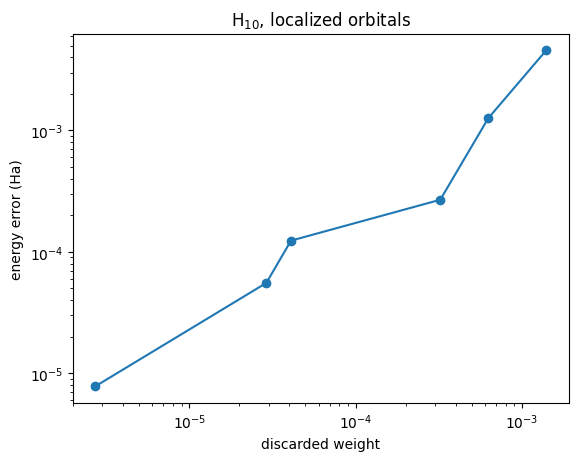

In [14]:
chis, dE, dw = [8, 12, 16, 20, 24, 32], [], []
for chi in chis:
    E, w, _ = run_dmrg(h1, g2, ec, 10, chi)
    dE.append(E - E_fci_h10)
    dw.append(w)
    print(f"chi = {chi:2d}: energy error = {dE[-1]:.1e} Ha, discarded weight = {w:.1e}")

slope = np.polyfit(np.log(dw), np.log(dE), 1)[0]
E_extrap = np.polyfit(dw[-3:], np.array(dE[-3:]) + E_fci_h10, 1)[1]
print(f"\nlog-log slope = {slope:.2f}")
print(f"extrapolated to zero discarded weight (3 largest chi): error = {E_extrap - E_fci_h10:+.1e} Ha")
plt.loglog(dw, dE, "o-")
plt.xlabel("discarded weight")
plt.ylabel("energy error (Ha)")
plt.title("H$_{10}$, localized orbitals");

The slope is close to 1, so the error is roughly proportional to the discarded weight, as for the TFIM, but the points scatter by a factor of a few: with symmetry blocks, $\chi$ is shared among sectors in uneven steps. A linear fit of $E$ against the discarded weight through the three best runs lands within about $10^{-5}$ Ha of FCI, as close as the best run itself. In practice, the extrapolation and the spread between fits are reported together as an estimate and its uncertainty (Baiardi and Reiher, review above).

### Which orbitals are entangled

The **single-orbital entropy** $s_p$ is the von Neumann entropy of the reduced density matrix of one orbital, a $4\times4$ matrix since $d = 4$ (J. Rissler, R. M. Noack and S. R. White, [arXiv:cond-mat/0508524](https://arxiv.org/abs/cond-mat/0508524); [Chem. Phys. 323, 519 (2006)](https://doi.org/10.1016/j.chemphys.2005.10.018)). It is 0 for an orbital that is surely empty or surely doubly occupied, and at most 2 bits. It is how DMRG users choose an active space: the orbitals with large $s_p$ are the ones that must be treated exactly. For N$_2$ near equilibrium and stretched:

R = 1.1: s_p = [0.   0.   0.08 0.07 0.36 0.36 0.11 0.38 0.38 0.15]  total = 1.88 bits


R = 2.4: s_p = [0.   0.   0.03 0.03 1.78 1.9  1.9  1.9  1.9  1.79]  total = 11.24 bits


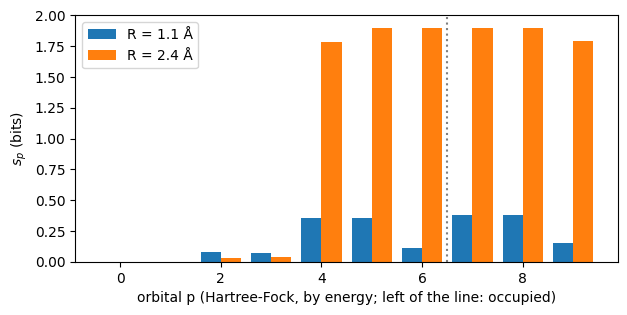

In [15]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for k, R in enumerate([1.1, 2.4]):
    mf = scf.RHF(nitrogen(R)).run()
    _, ne, _, ec_n, h1_n, g2_n, _ = itg.get_rhf_integrals(mf, g2e_symm=1)
    _, _, ket = run_dmrg(h1_n, g2_n, ec_n, ne, chi=200)
    s = driver.get_orbital_entropies(ket, orb_type=1) / np.log(2)  # bits
    ax.bar(np.arange(10) + 0.4 * k - 0.2, s, width=0.4, label=f"R = {R} Å")
    print(f"R = {R}: s_p =", np.round(s, 2), f" total = {s.sum():.2f} bits")
ax.axvline(6.5, color="gray", ls=":")
ax.set(xlabel="orbital p (Hartree-Fock, by energy; left of the line: occupied)", ylabel="$s_p$ (bits)", ylim=(0, 2))
ax.legend();

Orbitals 0 and 1 (the nitrogen 1s cores) carry no entropy at either length, so freezing them costs nothing. Near equilibrium the entropy is modest and sits in the bonding and antibonding orbitals of the triple bond (orbitals 4 to 9). Stretched, those six orbitals approach the 2-bit maximum: six electrons are shared among six orbitals with no dominant configuration. That is a (6 electrons, 6 orbitals) active space, chosen by measurement instead of by intuition.

## What the package adds

block2 runs the DMRG of the course, with engineering that matters for chemistry:

* **Any Hamiltonian.** `expr_builder` takes any sum of fermion or spin operator strings: a molecule, as here, or a lattice model. `get_qc_mpo` is a shortcut for the molecular case.
* **More symmetry.** `SymmetryTypes.SU2` works with total spin multiplets instead of $S_z$ states (3 per site instead of 4) and fixes the total spin $S$; with point-group labels (the last output of `get_rhf_integrals`) the blocks get smaller again.
* **Large active spaces**, up to about a hundred orbitals, with parallel and distributed sweeps (Zhai et al., above).
* **More than the energy:** excited states, density matrices, orbital entropies and dynamical correlation functions from the same MPS.

DMRG on large active spaces is also the classical reference that quantum algorithms for chemistry are compared against: S. Lee et al. ([arXiv:2208.02199](https://arxiv.org/abs/2208.02199); [Nat. Commun. 14, 1952 (2023)](https://doi.org/10.1038/s41467-023-37587-6)) weigh quantum phase estimation against classical methods such as DMRG for ground-state energies, and conclude that evidence for an exponential quantum advantage across chemistry has yet to be found.

In [16]:
shutil.rmtree(scratch, ignore_errors=True)

## Exercises

1. **Spin symmetry.** Rerun the H$_{10}$ order comparison with `SymmetryTypes.SU2` (make a new `DMRGDriver`). Print `driver.basis[0]`: how many states per site? At the same $\chi$, how do the errors and run times compare with `SZ`?
2. **A real basis set.** Take N$_2$ at $R = 2.0$ Å in the `6-31g` basis (18 orbitals). Freeze the two 1s cores and keep 8 orbitals with `get_rhf_integrals(mf, ncore=2, ncas=8)`, and check DMRG against PySCF's CASCI (`pyscf.mcscf.CASCI(mf, 8, 10)`). Then enlarge `ncas`: when does CASCI become too slow, and how large a $\chi$ does DMRG need to stay within 1 mHa of its own extrapolation?
3. **Random orders.** Run H$_{10}$ at $\chi = 16$ for ten random permutations of the localized orbitals. How wide is the spread of errors? Is the chain order the best one?
4. **Breaking many bonds.** Repeat the dissociation study for H$_{10}$, stretching all bonds together from 0.7 to 2.5 Å. Where does CCSD(T) fail, and how does the total orbital entropy $\sum_p s_p$ change along the curve?
5. **Your own model.** Write the Hubbard chain $H = -t\sum_{i,\sigma}(a^\dagger_{i\sigma}a_{i+1,\sigma} + \text{h.c.}) + U\sum_i n_{i\uparrow}n_{i\downarrow}$ on 10 sites at half filling with `expr_builder` (the interaction is the string `"cdCD"` on one site). At $U = 0$ the electrons are free, and the exact energy is the sum of the lowest eigenvalues of the $10\times10$ hopping matrix, filled once for each spin: check DMRG against it. Then turn on $U$ and watch the orbital entropies.